# Data Analysis

In [2]:
import os
import sys
sys.path.append("../../modules")

from intern.ihf import utils as utils

from intern.ihf.analysis import utilities as utls

from intern.ihf.ban import extract as extract
from intern.ihf.ban import plot as plot

from intern.ihf.bd_forests import extract as extract_bdf
from intern.ihf.bd_forests import plot as plot_bdf

In [3]:
import numpy as np, pandas as pd, geopandas as gpd
import matplotlib.pyplot as plt

In [4]:
import importlib
importlib.reload(utls)
importlib.reload(utils)
importlib.reload(extract)
importlib.reload(plot)

importlib.reload(extract_bdf)
importlib.reload(plot_bdf)

<module 'intern.ihf.bd_forests.plot' from 'c:\\Groupe_KC_AHA_Python\\main\\ihf\\../../modules\\intern\\ihf\\bd_forests\\plot.py'>

In [5]:
from intern.ihf.utils import CRS_M, D_MAX, BUFFERS, R_CLUSTER, KEY

In [6]:
adr = extract.read_concatenated_ban_files(extract.BAN_ADRESS_FILES)
occ = extract_bdf.read_bd_forests_file(extract_bdf.BD_FORESTS_FILE[0])
occ = occ[occ["exo_19"] == "BD FORET"]

c:\Groupe_KC_AHA_Python\main\ihf\../../modules\intern\ihf\ban\extract.py:40: DtypeWarning: Columns (16: nom_ld) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(path, sep=";") # sep=";" the ihf ban files are semicolon separated


Téléchargement de https://minio.lab.sspcloud.fr/khcoulibaly/diffusion/occupation_du_sol.zip


In [7]:
occ = occ.to_crs(CRS_M)
adr = adr[adr.type_position.isin(["bâtiment", "entrée"])]
adr = adr[adr.numero < 99999] # drops lieux-dits (BAN convention)
pts = (gpd.GeoDataFrame(adr, geometry=gpd.points_from_xy(adr.lon, adr.lat), crs=4326)
         .to_crs(CRS_M).reset_index(drop=True))

xmin, ymin, xmax, ymax = pts.total_bounds

In [8]:
print(xmin, ymin, xmax, ymax)

808919.216116847 6214615.46390461 1072263.8937493423 6448547.308180319


In [9]:
forest_typed = (occ.cx[xmin-D_MAX:xmax+D_MAX, ymin-D_MAX:ymax+D_MAX]
                [["niv3_19", "lib3_19", "geometry"]])
forest_mask = forest_typed.dissolve().explode(index_parts=False).reset_index(drop=True)

In [10]:
forest_typed.head()

,niv3_19,lib3_19,geometry
2,311,Forets de feuillus,"POLYGON ((880356 6298566, 880356 6298536, 8803..."
3,311,Forets de feuillus,"POLYGON ((978838.669 6240454.148, 978835.274 6..."
5,311,Forets de feuillus,"POLYGON ((990230.513 6242780.372, 990210.443 6..."
7,312,Forets de coniferes,"POLYGON ((982215.504 6382577.895, 982217.215 6..."
11,312,Forets de coniferes,"POLYGON ((982903.214 6417445.214, 982895 64174..."


In [11]:
pts["d_forest"] = utls.nearest(pts, forest_mask, D_MAX)["d"]

# addresses inside forest: negative distance to the edge
inside = pts.d_forest == 0
edges = gpd.GeoDataFrame(geometry=forest_mask.boundary, crs=CRS_M)
pts.loc[inside, "d_forest"] = -utls.nearest(pts[inside], edges)["d"]

pts["forest_type_nearest"] = utls.nearest(pts, forest_typed, D_MAX,
                                          cols=("geometry", "lib3_19"))["lib3_19"]

In [12]:
for r in BUFFERS:
    pts[f"forest_{r}m"], pts[f"dom_type_{r}m"] = utls.forest_share(pts, forest_typed, r)

In [13]:
xy = np.c_[pts.geometry.x, pts.geometry.y]
pts["cluster_size"], pts["cluster"] = utls.cluster_size(xy, R_CLUSTER)

TYPO_BINS, LABELS = [0, 3, 30, np.inf], ["isolated", "grouped", "dense"]
pts["typology"] = pd.cut(pts.cluster_size, TYPO_BINS, labels=LABELS)
pts["band"] = pd.cut(pts.d_forest.fillna(np.inf), [-np.inf, 0, 50, 100, 200, np.inf],
                     labels=["in forest", "≤50 m", "50–100 m", "100–200 m", ">200 m"])
pts["ihf"] = pts.d_forest <= 100

In [14]:
for r in (30, 50, 100):
    s, _ = utls.cluster_size(xy, r)
    print(r, pd.cut(s, TYPO_BINS, labels=LABELS).value_counts().round(3).to_dict())
    

30 {'isolated': 123814, 'grouped': 157033, 'dense': 979277}
50 {'isolated': 61695, 'grouped': 87118, 'dense': 1111311}
100 {'isolated': 22463, 'grouped': 44134, 'dense': 1193527}


band,in forest,≤50 m,50–100 m,100–200 m,>200 m,All
typology,,,,,,
isolated,13709,16821,7065,7796,16304,61695
grouped,7198,26613,15167,14160,23980,87118
dense,8854,111352,123096,180538,687471,1111311
All,29761,154786,145328,202494,727755,1260124


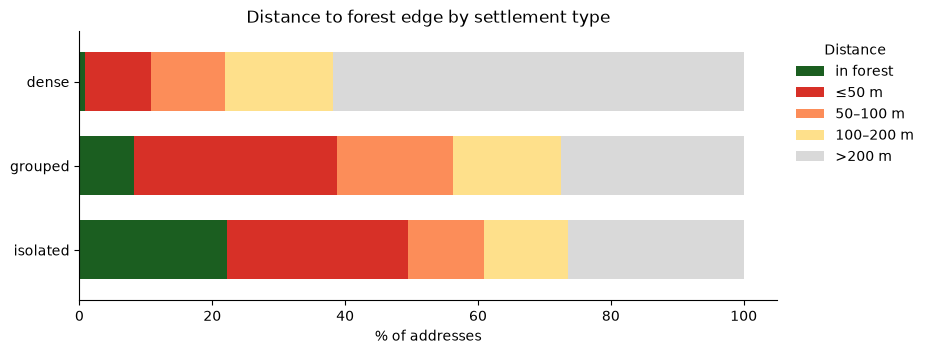

In [15]:
palette = {"in forest": "#1b5e20", "≤50 m": "#d73027", "50–100 m": "#fc8d59",
           "100–200 m": "#fee08b", ">200 m": "#d9d9d9"}
ct = pd.crosstab(pts.typology, pts.band, normalize="index").mul(100)
ax = ct.plot.barh(stacked=True, color=[palette[c] for c in ct.columns], figsize=(9, 3.5), width=.7)
ax.set(xlabel="% of addresses", ylabel="", title="Distance to forest edge by settlement type")
ax.legend(title="Distance", bbox_to_anchor=(1.01, 1), loc="upper left", frameon=False)
ax.spines[["top", "right"]].set_visible(False)

pd.crosstab(pts.typology, pts.band, margins=True).style.background_gradient(cmap="YlOrRd", axis=None)

In [16]:
from shapely import box
CELL = 500
pts["gx"], pts["gy"] = (pts.geometry.x // CELL).astype(int), (pts.geometry.y // CELL).astype(int)
grid = pts.groupby(["gx", "gy"]).agg(n=("ihf", "size"), p_ihf=("ihf", "mean")).reset_index()
grid = gpd.GeoDataFrame(grid, geometry=[box(x*CELL, y*CELL, (x+1)*CELL, (y+1)*CELL)
                        for x, y in zip(grid.gx, grid.gy)], crs=utils.CRS_M)
CARTO = f"https://basemaps.cartocdn.com/rastertiles/voyager/{{z}}/{{x}}/{{y}}.png?key={KEY}"
ATTR = "© OpenStreetMap contributors © CARTO"
grid[grid.n >= 5].explore("p_ihf", cmap="YlOrRd", vmin=0, vmax=1, tiles=CARTO, attr=ATTR,
                          style_kwds=dict(weight=0, fillOpacity=.75),
                          legend_kwds=dict(caption="Share of addresses ≤100 m from forest"))

In [17]:
import folium
sub = pts[pts.nom_commune == "Allons"]
b = sub.total_bounds
m = forest_typed.cx[b[0]-300:b[2]+300, b[1]-300:b[3]+300].explore(
        column="lib3_19", cmap="Greens", tiles=CARTO, attr=ATTR,
        style_kwds=dict(weight=.3), legend=False, name="Forest")
sub[["numero", "nom_voie", "d_forest", "typology", "band", "geometry"]].explore(
        m=m, column="band", categorical=True, cmap=list(palette.values()),
        marker_kwds=dict(radius=3), tooltip=["numero", "nom_voie", "d_forest", "typology"],
        name="Addresses")
folium.LayerControl().add_to(m); m

In [18]:
W = dict(dist=0.5, share=0.5)          # arbitrary: test sensitivity below
T_HIGH = 0.5                           # "high exposure" threshold, to justify

d = pts.d_forest.fillna(np.inf)
s_dist = np.where(d <= 0, 1.0, np.clip(1 - d / 200, 0, 1))
pts["score"] = W["dist"] * s_dist + W["share"] * pts["forest_100m"]
pts["high"] = pts.score >= T_HIGH

In [21]:
import requests

deps = ["04", "05", "06", "13", "83", "84"]
frames = []
for dep in deps:
    r = requests.get(
        f"https://geo.api.gouv.fr/departements/{dep}/communes",
        params={"format": "geojson", "geometry": "contour", "fields": "nom,code,surface"},
        timeout=60,
    )
    r.raise_for_status()
    frames.append(gpd.GeoDataFrame.from_features(r.json()["features"], crs=4326))

communes = (pd.concat(frames, ignore_index=True)
              .rename(columns={"code": "code_insee", "nom": "nom_commune"}))

In [22]:
communes.head()

,geometry,nom_commune,code_insee,surface
0,"POLYGON ((6.11111 44.05688, 6.11094 44.05703, ...",Aiglun,04001,1464.97
1,"POLYGON ((6.00251 43.7635, 6.00372 43.76468, 6...",Allemagne-en-Provence,04004,3313.49
2,"POLYGON ((6.57836 43.94706, 6.5778 43.94794, 6...",Allons,04005,4198.16
3,"POLYGON ((6.54528 44.32329, 6.54546 44.3233, 6...",Allos,04006,11722.66
4,"POLYGON ((6.57836 43.94706, 6.5772 43.94612, 6...",Angles,04007,998.46


In [23]:
pts["code_insee"] = pts.code_insee.astype(str).str.zfill(5)
pts["dep"] = pts.code_insee.str[:2]

communes = communes.to_crs(CRS_M)[["code_insee", "geometry"]]
communes["area_km2"] = communes.area / 1e6
forest_com = gpd.overlay(communes, forest_mask, how="intersection")
communes["forest_ha"] = (forest_com.assign(a=forest_com.area / 1e4)
                         .groupby("code_insee").a.sum()
                         .reindex(communes.code_insee).fillna(0).values)

com = (pts.groupby("code_insee")
          .agg(dep=("dep", "first"), n_addr=("score", "size"),
               score_mean=("score", "mean"), score_med=("score", "median"),
               p_high=("high", "mean"),
               p_isolated=("typology", lambda s: (s == "isolated").mean()))
          .reset_index()
          .merge(communes, on="code_insee"))
com["dens"] = com.n_addr / com.area_km2

In [24]:
bdiff = pd.read_csv(
    "../../data/fires/Incendies.csv",
    encoding="utf-8-sig",
    sep=None,
    engine="python",
    skiprows=3
)
bdiff = bdiff.rename(columns={
    "Année": "annee",
    "Surface parcourue (m2)": "area_m2",
    "Surface forêt (m2)": "area_forest_m2",
    "Code INSEE": "code_insee"
})

In [25]:
bdiff.head()

,annee,Numéro,Département,code_insee,Nom de la commune,Date de première alerte,area_m2,area_forest_m2,Surface maquis garrigues (m2),Autres surfaces naturelles hors forêt (m2),...,Surfaces non boisées artificialisées (m2),Surfaces non boisées (m2),Précision des surfaces,Type de peuplement,Nature,Décès ou bâtiments touchés,Nombre de décès,Nombre de bâtiments totalement détruits,Nombre de bâtiments partiellement détruits,Précision de la donnée
0,2016,4608,66,66225,Villelongue-dels-Monts,2016-01-01 15:37:00,10,10.0,NaN,NaN,...,NaN,NaN,NaN,3.0,Involontaire (particulier),NaN,NaN,NaN,NaN,NaN
1,2016,6821,66,66026,Brouilla,2016-01-02 11:56:00,10000,10000.0,0.0,NaN,...,NaN,NaN,NaN,2.0,Involontaire (travaux),NaN,NaN,NaN,NaN,NaN
2,2016,12337,66,66106,Maureillas-las-Illas,2016-01-04 13:30:00,20,NaN,20.0,NaN,...,NaN,NaN,NaN,4.0,Malveillance,NaN,NaN,NaN,NaN,NaN
3,2016,6,974,97424,Cilaos,2016-01-05 16:05:00,800,0.0,NaN,800.0,...,0.0,0.0,Estimées,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2016,7868,06,06086,Moulinet,2016-01-07 18:36:00,800,NaN,800.0,NaN,...,NaN,NaN,NaN,1.0,Involontaire (particulier),NaN,NaN,NaN,NaN,NaN


In [26]:
Y0, Y1 = 2010, 2025
N_YEARS = Y1 - Y0 + 1
fires = (bdiff[bdiff.annee.between(Y0, Y1)]
           .groupby("code_insee").size().rename("n_fires"))   # adapt column names
com = com.merge(fires, on="code_insee", how="left").fillna({"n_fires": 0})
sub = com[com.forest_ha >= 50].copy()      # drop communes with almost no forest
sub["rate"] = sub.n_fires / (sub.forest_ha / 1000) / N_YEARS

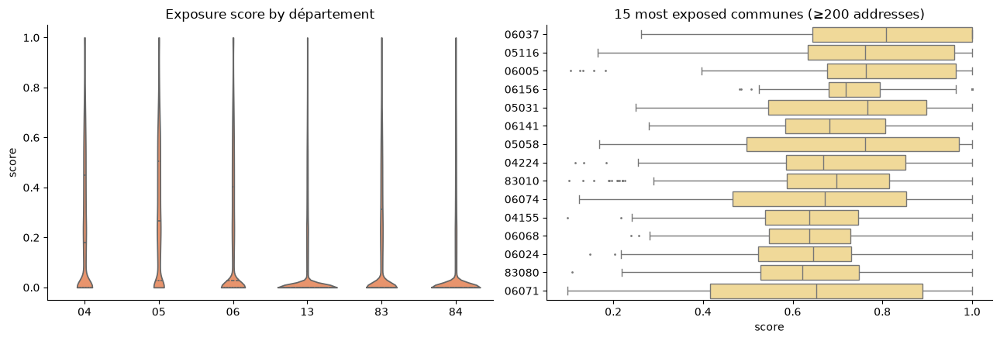

In [27]:
import seaborn as sns
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
sns.violinplot(data=pts, x="dep", y="score", inner="quartile", cut=0, ax=ax[0], color="#fc8d59")
ax[0].set(title="Exposure score by département", xlabel="", ylabel="score")
top = com[com.n_addr >= 200].nlargest(15, "score_mean").code_insee
sns.boxplot(data=pts[pts.code_insee.isin(top)], y="code_insee", x="score",
            order=top, ax=ax[1], color="#fee08b", fliersize=1)
ax[1].set(title="15 most exposed communes (≥200 addresses)", ylabel="")
sns.despine(); plt.tight_layout()

In [28]:
from scipy import stats
import statsmodels.formula.api as smf

sub["dens_cls"] = pd.qcut(sub.dens, 4, labels=["Q1 low", "Q2", "Q3", "Q4 high"])
sub["any_fire"] = sub.n_fires > 0

# 1) chi-squared + effect size
tab = pd.crosstab(sub.dens_cls, sub.any_fire)
chi2, p, dof, exp = stats.chi2_contingency(tab)
V = np.sqrt(chi2 / (tab.values.sum() * (min(tab.shape) - 1)))
print(f"chi2={chi2:.1f}, p={p:.2g}, Cramér V={V:.2f}, min expected={exp.min():.1f}")

# 2) Kruskal-Wallis on the fire rate + Spearman
H, p_kw = stats.kruskal(*[g.rate.values for _, g in sub.groupby("dens_cls", observed=True)])
rho, p_rho = stats.spearmanr(sub.dens, sub.rate)

# 3) negative binomial with exposure offset (the one to present)
m = smf.negativebinomial("n_fires ~ np.log(dens) + score_mean + C(dep)", data=sub,
                         offset=np.log(sub.forest_ha * N_YEARS)).fit(disp=0)
print(pd.concat([np.exp(m.params).rename("IRR"), np.exp(m.conf_int())], axis=1).round(2))

chi2=31.6, p=6.4e-07, Cramér V=0.19, min expected=35.5
               IRR     0      1
Intercept     0.00  0.00   0.00
C(dep)[T.05]  0.56  0.44   0.71
C(dep)[T.06]  2.53  2.02   3.18
C(dep)[T.13]  9.49  7.51  12.00
C(dep)[T.83]  1.53  1.23   1.89
C(dep)[T.84]  1.86  1.47   2.37
np.log(dens)  1.24  1.19   1.30
score_mean    0.19  0.12   0.31
alpha         1.86  1.72   2.02


In [29]:
from libpysal.weights import Queen
from esda.moran import Moran
from sklearn.metrics import roc_auc_score

mu, a = m.predict(), m.params["alpha"]
sub["res"] = (sub.n_fires - mu) / np.sqrt(mu + a * mu**2)
w = Queen.from_dataframe(sub, use_index=True); w.transform = "r"
print("Moran's I on residuals:", Moran(sub.res.values, w).I)

print("AUC score_mean:", roc_auc_score(sub.any_fire, sub.score_mean))
print("AUC forest area alone (baseline):", roc_auc_score(sub.any_fire, sub.forest_ha))

Moran's I on residuals: 0.1660289508881324
AUC score_mean: 0.3797364237920964
AUC forest area alone (baseline): 0.6135540275775387


c:\Groupe_KC_AHA_Python\.venv\Lib\site-packages\libpysal\weights\contiguity.py:347: UserWarning: The weights matrix is not fully connected: 
 There are 2 disconnected components.
  W.__init__(self, neighbors, ids=ids, **kw)


In [30]:
import folium
from folium.plugins import HeatMap

shadow = pts[(pts.typology == "isolated") & (pts.score >= T_HIGH)].to_crs(4326)
data = [[y, x, s] for x, y, s in zip(shadow.geometry.x, shadow.geometry.y, shadow.score)]

m = folium.Map(location=[43.9, 6.2], zoom_start=8, tiles=CARTO, attr=ATTR)
HeatMap(data, radius=12, blur=18, min_opacity=0.25,
        gradient={0.3: "#fee08b", 0.6: "#fc8d59", 1.0: "#b2182b"},
        name="Isolated, high exposure").add_to(m)
folium.LayerControl().add_to(m)
m.save("shadow_zones.html"); m